**Write the names of all group members (max. 5 members)**:

Giacomo Maggiore

Ugo Buzzacchino

Konstantin Krstevski

Julius Voss

Konstantinos Zisis


When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

Make sure all requested results are visible in the executed notebook. A concise **Project Report** is required at the end of the notebook.

# Exercise 1

### Question 1.a

Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

### Problem 1(a)

Let $f(t,w) = s_0 e^{\sigma w - \frac{1}{2}\sigma^2 t}$, so $S_t = f(t, W_t)$. The partial derivatives are

$$
\partial_t f = -\tfrac{1}{2}\sigma^2 f, \qquad \partial_w f = \sigma f, \qquad \partial_{ww} f = \sigma^2 f.
$$

By Itô's formula,

$$
dS_t = \Big(\partial_t f + \tfrac{1}{2}\partial_{ww} f\Big)dt + \partial_w f\, dW_t
= \Big(-\tfrac{1}{2}\sigma^2 + \tfrac{1}{2}\sigma^2\Big) S_t\, dt + \sigma S_t\, dW_t
= \sigma S_t\, dW_t .
$$

Since $W_0 = 0$, we have $S_0 = s_0$. Hence $S_t$ solves SDE (1) with $r = 0$. 

### Question 1.b - Generate dataset

In [1]:
import math
from torch.distributions import Normal
from torch.utils.data import DataLoader, TensorDataset
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [2]:
# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
# Use the exact geometric Brownian motion update specified in Problem 1(b).
# Each path contains N+1=31 prices, including S0 and ST.
import numpy as np

K, N, s0, T, sigma, r = 1.0, 30, 1.0, 0.25, 0.35, 0.0
dt = T / N

def simulate_gbm(m, rng):
    Z = rng.standard_normal((m, N))
    log_incr = -0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * Z
    log_S = np.concatenate([np.zeros((m, 1)), np.cumsum(log_incr, axis=1)], axis=1)
    return s0 * np.exp(log_S)  

rng = np.random.default_rng(0)
# Generate the training set
S_train = simulate_gbm(100_000, rng)
# Generate the test set
S_test = simulate_gbm(10_000, rng)
print(S_train.shape, S_test.shape) 

(100000, 31) (10000, 31)


### Question 1.c - Model implementation

In [3]:
# Implement the deep hedging model from scratch.
import torch
import torch.nn as nn

torch.manual_seed(0)

### Model implementation

N = 30     # number of trading dates t_0, ..., t_{N-1}
nh1 = 32   # neurons in first hidden layer
nh2 = 32   # neurons in second hidden layer

def make_network():
    return nn.Sequential(nn.Linear(1, nh1),
                         nn.Tanh(),
                         nn.Linear(nh1, nh2),
                         nn.Tanh(),
                         nn.Linear(nh2, 1))

# 30 separate networks H_0, ..., H_29, each with its own parameters
H = nn.ModuleList([make_network() for _ in range(N)])
# Each network takes the current stock price as input and returns the shares to hold.

# Do not use future prices as inputs to the trading decision.

### Question 1.d - Model training

p = C(0, s0) = 0.069726


  0%|          | 0/100 [00:00<?, ?it/s]

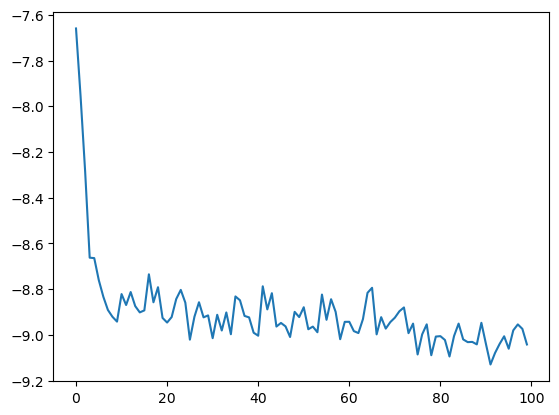

In [4]:
def hedge_positions(S):

    return torch.cat([H[j](S[:, j:j+1]) for j in range(N)], dim=1)
# Implement the call payoff with strike K=1 and maturity T=1/4 year.
def payoff(S_T, K=K):
    return torch.clamp(S_T - K, min=0.0)

# Implement the Black-Scholes call-price formula (3).
def bs_call_price(t, s, K=K, T=T, sigma=sigma, r=r):
    s = torch.as_tensor(s, dtype=torch.float32)
    tau = T - t
    d_plus = (torch.log(s / K) + (r + 0.5 * sigma**2) * tau) / (sigma * math.sqrt(tau))
    d_minus = d_plus - sigma * math.sqrt(tau)
    Phi = Normal(0.0, 1.0).cdf
    return Phi(d_plus) * s - Phi(d_minus) * K * math.exp(-r * tau)
# Compute and fix the initial premium p=C(0,s0); p is not trained.
p = bs_call_price(0.0, s0).item()
print(f"p = C(0, s0) = {p:.6f}")

# Train all 30 networks jointly by minimizing equation (2) on the training set.
# Define training hyperparameters
n_epochs = 100
lr = 1e-2 # learning rate
batch_size = 1000
milestones = [75]

# Instantiate an optimizer (only the network parameters are trained; p is fixed)
optimizer = torch.optim.Adam(H.parameters(), lr=lr)

# Instantiate a scheduler to decrease the learning rate during training according to a pre-defined rule
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.1)

# Create a batch loader from the training paths
dataset = TensorDataset(torch.as_tensor(S_train, dtype=torch.float32))
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

### Training

losses = torch.empty(n_epochs)
training_loop = tqdm(range(n_epochs))
for epoch in training_loop:

    # At each epoch iterate over batches
    for S, in loader:
        # compute training loss (2) on batch
        dS = S[:, 1:] - S[:, :-1]
        pnl = p + torch.sum(hedge_positions(S) * dS, dim=1) - payoff(S[:, -1])
        loss = torch.mean(pnl**2)
        # compute gradient of training loss wrt parameters
        loss.backward()
        # do one gradient step
        optimizer.step()
        # reset the computational graph
        optimizer.zero_grad()

    # Print loss in the progression bar
    training_loop.set_postfix(loss = loss.item())

    # decrease learning rate according to scheduler's settings
    scheduler.step()

    # save training loss for plotting
    losses[epoch] = loss.item()

plt.plot(torch.log(losses), label='Training loss')
plt.show()

### Question 1.e - Model evaluation

Deep hedge P&L on test set: mean = -2.29e-06, std = 0.0111


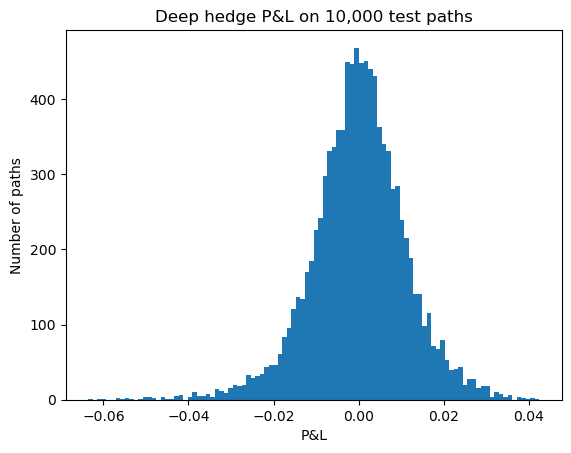

In [5]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# Compute P&L = p + sum_j H_j(S_tj)*(S_tj+1-S_tj) - g(ST).
S_test = torch.as_tensor(S_test, dtype=torch.float32)

# P&L = p + sum_j H_j(S_tj) * (S_tj+1 - S_tj) - g(S_T), with trained networks frozen
with torch.no_grad():
    dS_test = S_test[:, 1:] - S_test[:, :-1]
    pnl_nn = p + torch.sum(hedge_positions(S_test) * dS_test, dim=1) - payoff(S_test[:, -1])

print(f"Deep hedge P&L on test set: mean = {pnl_nn.mean().item():.2e}, std = {pnl_nn.std().item():.4f}")


# Plot its histogram and print the empirical mean and standard deviation.
plt.hist(pnl_nn.numpy(), bins=100)
plt.xlabel("P&L")
plt.ylabel("Number of paths")
plt.title("Deep hedge P&L on 10,000 test paths")
plt.show()

### Question 1.f(i) - Compute analytical solution

Show a **step-by-step** derivation of the analytical hedging strategy:

With $\tau = T - t$, $r = 0$, $\varphi = \Phi'$ the standard normal density, and
$C(t,s) = s\,\Phi(d_+) - K\,\Phi(d_-)$, where $d_+ = \frac{\log(s/K) + \frac12\sigma^2\tau}{\sigma\sqrt{\tau}}$ and $d_- = d_+ - \sigma\sqrt{\tau}$:

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \frac{\partial}{\partial s}\big[s\,\Phi(d_+)\big] - K\,\frac{\partial}{\partial s}\Phi(d_-) \\
& = \Phi(d_+) + s\,\varphi(d_+)\,\frac{\partial d_+}{\partial s} - K\,\varphi(d_-)\,\frac{\partial d_-}{\partial s} \\
& = \Phi(d_+) + \frac{1}{s\,\sigma\sqrt{\tau}}\Big(s\,\varphi(d_+) - K\,\varphi(d_-)\Big)
&& \text{(since } \tfrac{\partial d_+}{\partial s} = \tfrac{\partial d_-}{\partial s} = \tfrac{1}{s\,\sigma\sqrt{\tau}}\text{)} \\
& = \Phi(d_+)
&& \text{(since } K\,\varphi(d_-) = s\,\varphi(d_+)\text{, shown below)}
\end{align*}

The last step uses $d_- = d_+ - \sigma\sqrt{\tau}$:

\begin{align*}
\varphi(d_-) & = \frac{1}{\sqrt{2\pi}}\, e^{-\frac12 (d_+ - \sigma\sqrt{\tau})^2}
= \varphi(d_+)\, e^{\,d_+\sigma\sqrt{\tau} - \frac12\sigma^2\tau}
= \varphi(d_+)\, e^{\,\log(s/K)}
= \varphi(d_+)\,\frac{s}{K}.
\end{align*}

Hence
$$
\boxed{\,H^{\text{BS}}_t(s) = \Phi(d_+) = \Phi\!\left(\frac{\log(s/K) + \frac12\sigma^2 (T-t)}{\sigma\sqrt{T-t}}\right)\,}
$$

No points for solutions without explicit derivation.

### Question 1.f(ii) - P&L comparison with the analytical hedge

Deep hedge P&L: mean = -2.29e-06, std = 0.0111
BS delta P&L:   mean = 5.85e-06, std = 0.0111


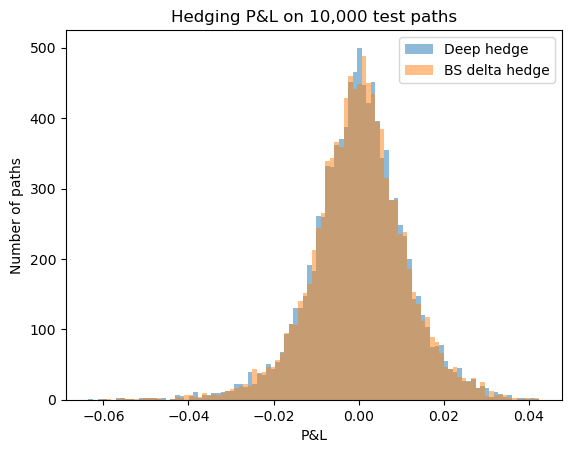

In [6]:
# Implement the formula you found
def bs_delta(t, s, K=K, T=T, sigma=sigma):
    # H^BS_t(s) = Phi(d_+), with r = 0
    tau = T - t
    d_plus = (torch.log(s / K) + 0.5 * sigma**2 * tau) / (sigma * torch.sqrt(tau))
    return Normal(0.0, 1.0).cdf(d_plus)

# Rebalance at t_0,...,t_29 using the same test paths, premium and payoff as in 1.e.
t_grid = torch.arange(N) * T / N                       # t_0, ..., t_29
positions_bs = bs_delta(t_grid, S_test[:, :-1])        # (10000, 30), column j = H^BS_{t_j}(S_{t_j})

# Compute P&L using the same sign convention as in 1.e.
pnl_bs = p + torch.sum(positions_bs * dS_test, dim=1) - payoff(S_test[:, -1])

# Plot histograms of both P&L distributions and print their means and standard deviations.
print(f"Deep hedge P&L: mean = {pnl_nn.mean().item():.2e}, std = {pnl_nn.std().item():.4f}")
print(f"BS delta P&L:   mean = {pnl_bs.mean().item():.2e}, std = {pnl_bs.std().item():.4f}")

bins = torch.linspace(min(pnl_nn.min(), pnl_bs.min()).item(), max(pnl_nn.max(), pnl_bs.max()).item(), 100).numpy()
plt.hist(pnl_nn.numpy(), bins=bins, alpha=0.5, label="Deep hedge")
plt.hist(pnl_bs.numpy(), bins=bins, alpha=0.5, label="BS delta hedge")
plt.xlabel("P&L")
plt.ylabel("Number of paths")
plt.title("Hedging P&L on 10,000 test paths")
plt.legend()
plt.show()

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs (does not help)
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$) (Works)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

### Question 1.g - Learned strategy comparison with analytical solution

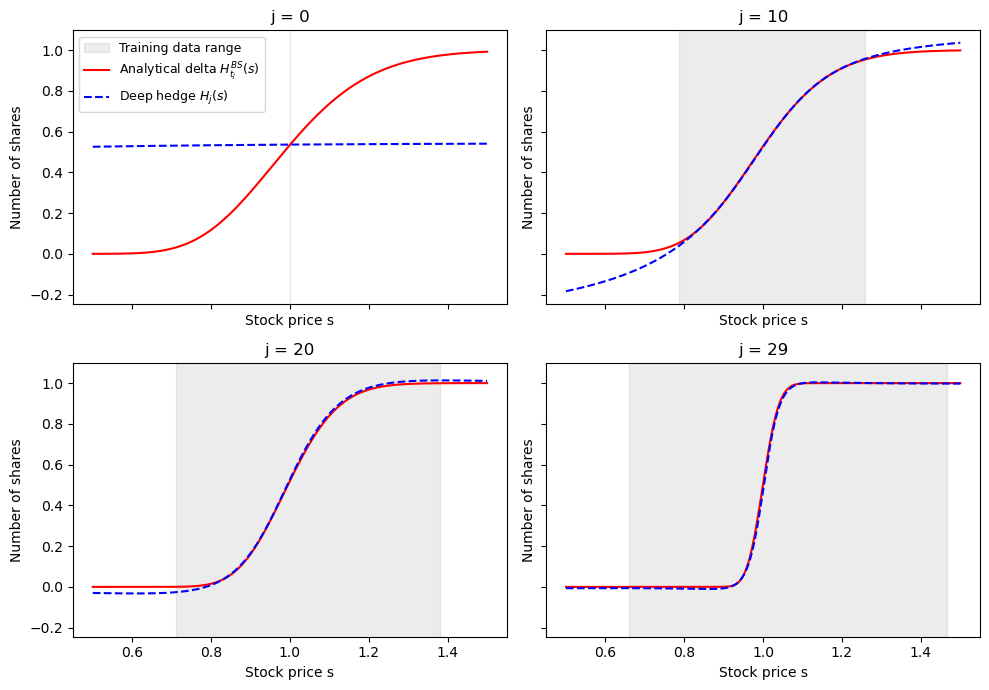

In [7]:
# Compare the hedge functions at j=0,10,20,29.
# Make a grid of stock prices s in [0.5,1.5].
# Create four plots or panels, one per selected date.
# In each panel, overlay H_j(s) and the analytical delta evaluated on the same price grid.
# Label the date, both strategies, and axes (stock price and number of shares).

s_grid = torch.linspace(0.5, 1.5, 200).unsqueeze(1)   # (200, 1), input shape for the networks
S_train = torch.as_tensor(S_train, dtype=torch.float32)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, j in zip(axes.flat, [0, 10, 20, 29]):
    t_j = torch.tensor(j * T / N)
    with torch.no_grad():
        h_nn = H[j](s_grid).squeeze(1)
    h_bs = bs_delta(t_j, s_grid.squeeze(1))

    # Range of training prices at t_j (1st-99th percentile): where H_j actually saw data
    lo, hi = torch.quantile(S_train[:, j], torch.tensor([0.01, 0.99]))
    ax.axvspan(lo.item(), hi.item(), color="gray", alpha=0.15, label="Training data range")

    ax.plot(s_grid.squeeze(1), h_bs, "r-", label="Analytical delta $H^{BS}_{t_j}(s)$")
    ax.plot(s_grid.squeeze(1), h_nn, "b--", label="Deep hedge $H_j(s)$")
    ax.set_title(f"j = {j}")
    ax.set_xlabel("Stock price s")
    ax.set_ylabel("Number of shares")

axes[0, 0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("output/1g_hedge_comparison.png", dpi=150)
plt.show()

- For what times $t_j$ are the two functions most similar?

The functions are most similar at the later dates ($j = 20, 29$). At $j = 0$ they agree only near $s = 1$.

- Why?

Each network $H_j$ is trained only on the prices $S_{t_j}$ observed in the training set, so it can only learn delta where it sees data. At $t_0$ every path starts at $s_0 = 1$, so $H_0$ sees a single input value: it is accurate at $s = 1$ and unconstrained elsewhere on $[0.5, 1.5]$. As time passes, the paths spread out, since $\operatorname{Var}(\log S_{t_j}) = \sigma^2 t_j$ grows linearly in $t_j$. The later networks therefore see prices across most of $[0.5, 1.5]$ and match delta over a much wider range (the shaded data range in the plots). Outside the data range, a network extrapolates, and nothing in the loss forces it to agree with delta there.


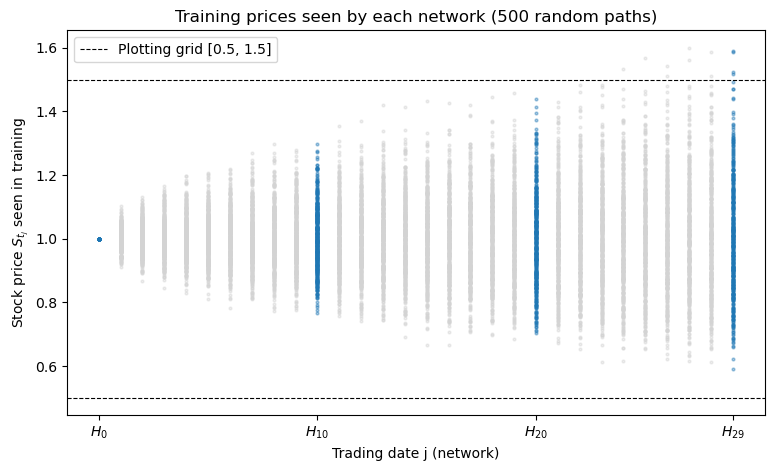

H_0 : 98% of training prices in [1.000, 1.000]
H_10: 98% of training prices in [0.787, 1.258]
H_20: 98% of training prices in [0.710, 1.379]
H_29: 98% of training prices in [0.660, 1.467]


In [8]:
### What each network H_j has seen during training

S_train = torch.as_tensor(S_train, dtype=torch.float32)
n_show = 500                                           
idx = torch.randperm(S_train.shape[0])[:n_show]
selected = [0, 10, 20, 29]

plt.figure(figsize=(9, 5))
for j in range(N):
    color = "tab:blue" if j in selected else "lightgray"
    plt.scatter(torch.full((n_show,), j), S_train[idx, j], s=4, color=color, alpha=0.4)

# Plotting grid used in 1.g
plt.axhline(0.5, color="black", linestyle="--", linewidth=0.8, label="Plotting grid [0.5, 1.5]")
plt.axhline(1.5, color="black", linestyle="--", linewidth=0.8)

plt.xticks(selected, [f"$H_{{{j}}}$" for j in selected])
plt.xlabel("Trading date j (network)")
plt.ylabel("Stock price $S_{t_j}$ seen in training")
plt.title(f"Training prices seen by each network ({n_show} random paths)")
plt.legend(loc="upper left")
plt.savefig("output/1g_training_data_seen.png", dpi=150)
plt.show()

# Print the observed price range for the selected networks (all 100,000 paths)
for j in selected:
    lo, hi = torch.quantile(S_train[:, j], torch.tensor([0.01, 0.99]))
    print(f"H_{j:<2}: 98% of training prices in [{lo:.3f}, {hi:.3f}]")

# Exercise 2

### Question 2.a - Generate dataset

In [9]:
# Generate 100,000 training paths and 10,000 independent test paths of (S,V).
# Parameters: N=30, s0=1, T=1/4 year, rho=-0.3, a=4, b=0.5, v0=0.5, sigma=1.
# Each stock and variance path contains N+1=31 values.

# (i) Write a function to simulate V using the exact noncentral chi-square transitions.

# (ii) Write a function to simulate S using the supplied simplified Broadie-Kaya update.

### Question 2.b - Model implementation

In [10]:
# Implement the deep hedging model for a generic AVaR level alpha.
# Create 30 separate networks, each taking (current stock price, current variance)
# as input and returning one stock holding.
# Implement the AVaR objective in equation (6), with a trainable scalar threshold w.

### Question 2.c - Model training

In [11]:
# Train two separate deep hedging models for alpha=0.5 and alpha=0.9.
# Use the call option with strike K=1 and maturity T=1/4 year.
# Minimize equation (6), jointly optimizing all network parameters and scalar w.
# Each model has its own networks and one threshold w shared across its paths.
# Include w in the optimizer; do not fix a Black-Scholes premium in this objective.

### Question 2.d - Price comparison

In [12]:
# Freeze each trained model and its threshold w.
# Evaluate equation (6) on the same 10,000 test paths to estimate each price p.
# Print p for alpha=0.5 and alpha=0.9.
# Explain which price is higher and why.

### Question 2.e - P&L comparison

In [13]:
# Compute test P&L for alpha=0.5 and alpha=0.9.
# Use the same test paths for both models.
# Plot both P&L histograms with comparable axes and binning.
# Print the empirical mean and standard deviation for each distribution.

## Project Report

Provide a concise synthesis of your findings across both problems. Refer to the results above and focus on the main conclusions.

### Approach

Briefly describe how you simulated the paths, trained the hedges, and evaluated them on the test sets.

### Key results

Summarize the comparison between the learned hedge and Black–Scholes delta. For Heston, report the two estimated premiums and the main differences in test P&L.

### Interpretation

Explain how closely the learned holdings matched delta at the selected dates and how the AVaR level affected the premium and the P&L distribution.

### Robustness

Discuss how simulation noise and random network initialization could affect your conclusions. No additional experiments are required.

### Limitations

Discuss the main limitations, such as discrete rebalancing and reliance on simulated markets.